<a href="https://www.kaggle.com/code/naveenkumartiwari/emotion-detection-from-text-ipynb?scriptVersionId=357923069" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:

# ============================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ============================================

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# TensorFlow and Keras for deep learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Machine learning evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Utilities for timing and reproducibility
import time
import random

# Set random seeds to make experiments more reproducible
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Display library versions
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

# Check whether a GPU is available
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
NumPy version: 2.1.3
Available GPUs: []


2026-10-13 08:14:39.603921: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [2]:

# ============================================
# CELL 2: INSTALL DATASET LIBRARY
# ============================================

# Install the library used to load the Hugging Face dataset.
# Kaggle's internet setting must be enabled for this download.
%pip -q install datasets


Note: you may need to restart the kernel to use updated packages.


In [3]:

# ============================================
# CELL 3: LOAD THE EMOTION DATASET
# ============================================

from datasets import load_dataset

# Download the DAIR.AI Emotion dataset.
# The dataset already contains train, validation and test splits.
dataset = load_dataset("dair-ai/emotion")

# Print the available dataset splits and their sizes.
print(dataset)

# Display one example from the training set.
print("\nExample training record:")
print(dataset["train"][0])

# Display the emotion label names.
label_names = dataset["train"].features["label"].names
print("\nEmotion classes:", label_names)

# Count the number of emotion classes.
NUM_CLASSES = len(label_names)

print("Number of classes:", NUM_CLASSES)


README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Example training record:
{'text': 'i didnt feel humiliated', 'label': 0}

Emotion classes: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Number of classes: 6


In [4]:
dataset['train'][12]

{'text': 'i think it s the easiest time of year to feel dissatisfied',
 'label': 3}

In [5]:
# ============================================
# CELL 4: CONVERT DATA INTO DATAFRAMES
# ============================================

# Convert each split into a Pandas DataFrame.
train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# Convert numerical emotion labels into readable emotion names.
# This makes our exploratory analysis easier to understand.
for df in [train_df, val_df, test_df]:
    df["emotion"] = df["label"].apply(lambda x: label_names[x])

# Display the first five training examples.
display(train_df.head())

# Display dataset dimensions.
print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

# Check for missing text values.
print("\nMissing training texts:", train_df["text"].isna().sum())

# Check for duplicate training texts.
print("Duplicate training texts:", train_df["text"].duplicated().sum())


,text,label,emotion
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


Training shape: (16000, 3)
Validation shape: (2000, 3)
Test shape: (2000, 3)

Missing training texts: 0
Duplicate training texts: 31


In [6]:
train_df

,text,label,emotion
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger
...,...,...,...
15995,i just had a very brief time in the beanbag an...,0,sadness
15996,i am now turning and i feel pathetic that i am...,0,sadness
15997,i feel strong and good overall,1,joy
15998,i feel like this was such a rude comment and i...,3,anger


emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


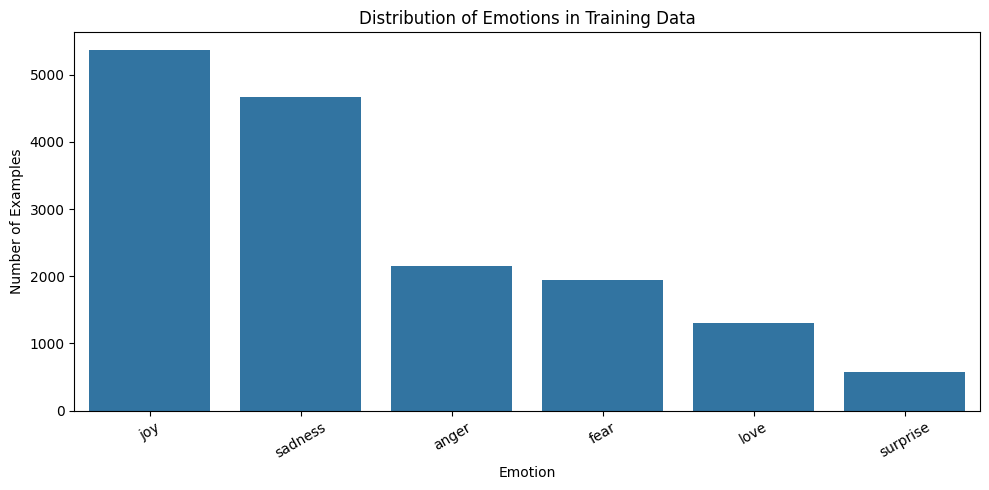

In [7]:

# ============================================
# CELL 5: EMOTION DISTRIBUTION
# ============================================

# Count how many examples belong to each emotion.
emotion_counts = train_df["emotion"].value_counts()

# Print the counts.
print(emotion_counts)

# Plot the number of examples for each emotion.
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train_df,
    x="emotion",
    order=emotion_counts.index
)

plt.title("Distribution of Emotions in Training Data")
plt.xlabel("Emotion")
plt.ylabel("Number of Examples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [8]:
# ============================================
# CELL 6: VIEW EXAMPLES FROM EACH EMOTION
# ============================================

# Use a fixed random state so the sampled examples are reproducible.
for emotion in label_names:

    print(f"\n{'=' * 60}")
    print("EMOTION:", emotion.upper())
    print("=" * 60)

    # Select three random text examples for this emotion.
    examples = train_df.loc[
        train_df["emotion"] == emotion, "text"
    ].sample(n=3, random_state=SEED)

    # Print each example.
    for text in examples:
        print("-", text)



EMOTION: SADNESS
- im feeling so lousy they tried to cheer me up during school time and during choir practice
- i feel highly disadvantaged
- i feel humiliated to introduce you to my colleagues as my wife

EMOTION: JOY
- i feel im rather innocent in that respect
- im feeling quite adventurous and tried out those drinks that i just normally read through the pages of pocketbooks
- im feeling much more positive about the impending move

EMOTION: LOVE
- i mean fuck i feel like i was way more considerate with customers and concerned about appearance and sanitiation snoozel pm but fine
- i remember a couple of years ago i was feeling romantic and dreamy and asked him wonder if we ll celebrate our th anniversary
- im so going to end up feeling slutty and be like ah

EMOTION: ANGER
- i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
- i feel frustrated sometimes with my mac lipsticks

In [9]:
# ============================================
# CELL 7: SEPARATE FEATURES AND TARGET LABELS
# ============================================

# Extract input text from each dataset split.
# These sentences will be the inputs to our neural networks.
X_train_text = train_df["text"].astype(str).to_numpy()
X_val_text = val_df["text"].astype(str).to_numpy()
X_test_text = test_df["text"].astype(str).to_numpy()

# Extract numerical emotion labels.
# Each label is an integer from 0 to 5.
y_train = train_df["label"].to_numpy(dtype=np.int32)
y_val = val_df["label"].to_numpy(dtype=np.int32)
y_test = test_df["label"].to_numpy(dtype=np.int32)

# Print the shapes to verify that the data was extracted correctly.
print("Training text shape:", X_train_text.shape)
print("Training labels shape:", y_train.shape)

print("Validation text shape:", X_val_text.shape)
print("Validation labels shape:", y_val.shape)

print("Test text shape:", X_test_text.shape)
print("Test labels shape:", y_test.shape)

# Display one text example and its corresponding emotion.
print("\nExample text:", X_train_text[0])
print("Numerical label:", y_train[0])
print("Emotion:", label_names[y_train[0]])

Training text shape: (16000,)
Training labels shape: (16000,)
Validation text shape: (2000,)
Validation labels shape: (2000,)
Test text shape: (2000,)
Test labels shape: (2000,)

Example text: i didnt feel humiliated
Numerical label: 0
Emotion: sadness


In [10]:
X_train_text

array(['i didnt feel humiliated',
       'i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake',
       'im grabbing a minute to post i feel greedy wrong', ...,
       'i feel strong and good overall',
       'i feel like this was such a rude comment and im glad that t',
       'i know a lot but i feel so stupid because i can not portray it'],
      dtype=object)

In [11]:
y_train

array([0, 0, 3, ..., 1, 3, 0], dtype=int32)

In [12]:
# ============================================
# CELL 8: DEFINE TEXT PREPROCESSING SETTINGS
# ============================================

# Maximum number of vocabulary entries, including reserved tokens.
MAX_TOKENS = 10_000

# Every text sequence will contain exactly 50 token positions.
MAX_SEQUENCE_LENGTH = 50

# Create a text vectorization layer.
# It will lowercase text, split it into tokens, and assign integer IDs.
text_vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    standardize="lower_and_strip_punctuation",
    split="whitespace",
    output_mode="int",
    output_sequence_length=MAX_SEQUENCE_LENGTH
)

# Learn the vocabulary ONLY from the training text.
# This prevents information from validation or test text from influencing
# the vocabulary-building process.
text_vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train_text).batch(256)
)

# Retrieve the vocabulary learned by the vectorizer.
vocabulary = text_vectorizer.get_vocabulary()

# Count the tokens in the learned vocabulary.
VOCAB_SIZE = len(vocabulary)

print("Vocabulary size:", VOCAB_SIZE)
print("Maximum vocabulary setting:", MAX_TOKENS)

# Display some vocabulary entries and their corresponding token IDs.
print("\nFirst 20 vocabulary entries:")
for token_id, token in enumerate(vocabulary[:200]):
    print(f"ID {token_id}: {token}")
vocabulary

Vocabulary size: 10000
Maximum vocabulary setting: 10000

First 20 vocabulary entries:
ID 0: 
ID 1: [UNK]
ID 2: i
ID 3: feel
ID 4: and
ID 5: to
ID 6: the
ID 7: a
ID 8: that
ID 9: feeling
ID 10: of
ID 11: my
ID 12: in
ID 13: it
ID 14: like
ID 15: so
ID 16: for
ID 17: im
ID 18: me
ID 19: but
ID 20: was
ID 21: have
ID 22: is
ID 23: this
ID 24: am
ID 25: with
ID 26: not
ID 27: about
ID 28: be
ID 29: as
ID 30: on
ID 31: you
ID 32: just
ID 33: at
ID 34: when
ID 35: or
ID 36: all
ID 37: because
ID 38: more
ID 39: do
ID 40: can
ID 41: really
ID 42: up
ID 43: t
ID 44: are
ID 45: by
ID 46: very
ID 47: know
ID 48: been
ID 49: if
ID 50: out
ID 51: myself
ID 52: time
ID 53: how
ID 54: what
ID 55: get
ID 56: little
ID 57: had
ID 58: now
ID 59: will
ID 60: from
ID 61: being
ID 62: they
ID 63: people
ID 64: them
ID 65: would
ID 66: he
ID 67: want
ID 68: her
ID 69: some
ID 70: think
ID 71: one
ID 72: still
ID 73: ive
ID 74: him
ID 75: even
ID 76: who
ID 77: an
ID 78: life
ID 79: its
ID 80: there
ID 81:

['',
 '[UNK]',
 np.str_('i'),
 np.str_('feel'),
 np.str_('and'),
 np.str_('to'),
 np.str_('the'),
 np.str_('a'),
 np.str_('that'),
 np.str_('feeling'),
 np.str_('of'),
 np.str_('my'),
 np.str_('in'),
 np.str_('it'),
 np.str_('like'),
 np.str_('so'),
 np.str_('for'),
 np.str_('im'),
 np.str_('me'),
 np.str_('but'),
 np.str_('was'),
 np.str_('have'),
 np.str_('is'),
 np.str_('this'),
 np.str_('am'),
 np.str_('with'),
 np.str_('not'),
 np.str_('about'),
 np.str_('be'),
 np.str_('as'),
 np.str_('on'),
 np.str_('you'),
 np.str_('just'),
 np.str_('at'),
 np.str_('when'),
 np.str_('or'),
 np.str_('all'),
 np.str_('because'),
 np.str_('more'),
 np.str_('do'),
 np.str_('can'),
 np.str_('really'),
 np.str_('up'),
 np.str_('t'),
 np.str_('are'),
 np.str_('by'),
 np.str_('very'),
 np.str_('know'),
 np.str_('been'),
 np.str_('if'),
 np.str_('out'),
 np.str_('myself'),
 np.str_('time'),
 np.str_('how'),
 np.str_('what'),
 np.str_('get'),
 np.str_('little'),
 np.str_('had'),
 np.str_('now'),
 np.str_

In [13]:
# ============================================
# CELL 9: VECTORIZE TRAIN, VALIDATION AND TEST
# ============================================

# Convert training sentences into integer sequences.
# Output shape: (number_of_training_examples, 50)
X_train = text_vectorizer(
    tf.constant(X_train_text)
).numpy()

# Convert validation sentences using the SAME vocabulary.
X_val = text_vectorizer(
    tf.constant(X_val_text)
).numpy()

# Convert test sentences using the SAME vocabulary.
X_test = text_vectorizer(
    tf.constant(X_test_text)
).numpy()

# Display the dimensions of the processed datasets.
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

# Display the original sentence and its numerical representation.
example_index = 0

print("\nOriginal sentence:")
print(X_train_text[example_index])

print("\nNumerical sequence:")
print(X_train[example_index])

# Convert the non-padding token IDs back to words for verification.
print("\nTokens represented by the sequence:")
print([
    vocabulary[token_id]
    for token_id in X_train[example_index]
    if token_id != 0
])


X_train shape: (16000, 50)
X_val shape: (2000, 50)
X_test shape: (2000, 50)

Original sentence:
i didnt feel humiliated

Numerical sequence:
[  2 140   3 686   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]

Tokens represented by the sequence:
[np.str_('i'), np.str_('didnt'), np.str_('feel'), np.str_('humiliated')]


Shortest sequence: 2
Longest sequence after truncation: 50
Average sequence length: 19.1
Average padding positions: 30.9


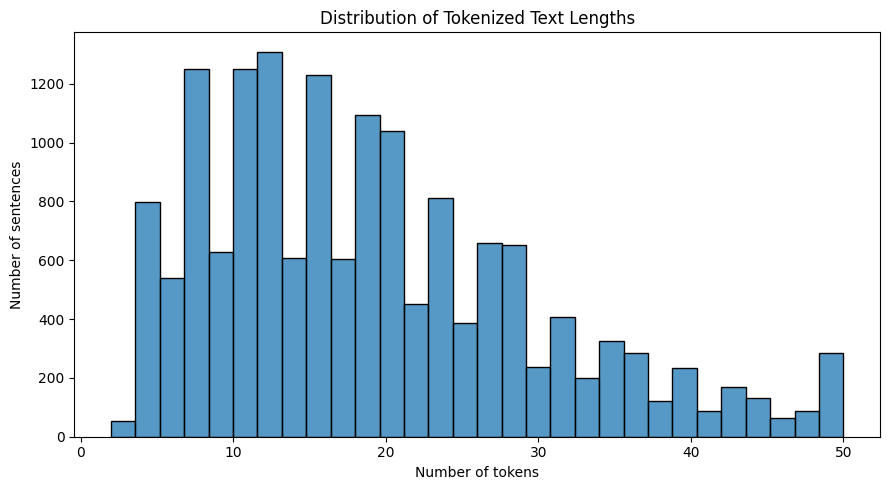

Percentage of first 100 sequences with 50 positions filled: 100.0 %


In [14]:
# ============================================
# CELL 10: ANALYZE SEQUENCE LENGTHS AND PADDING
# ============================================

# Count non-padding tokens in each processed training sentence.
# Since zero is the padding ID, every nonzero entry is a token.
sequence_lengths = np.count_nonzero(X_train, axis=1)

# Calculate how many padding positions each sentence contains.
padding_lengths = MAX_SEQUENCE_LENGTH - sequence_lengths

print("Shortest sequence:", sequence_lengths.min())
print("Longest sequence after truncation:", sequence_lengths.max())
print("Average sequence length:", round(sequence_lengths.mean(), 2))
print("Average padding positions:", round(padding_lengths.mean(), 2))

# Plot the distribution of sequence lengths.
plt.figure(figsize=(9, 5))

sns.histplot(sequence_lengths, bins=30)

plt.title("Distribution of Tokenized Text Lengths")
plt.xlabel("Number of tokens")
plt.ylabel("Number of sentences")
plt.tight_layout()
plt.show()

# Plot the percentage of sentences that reach the maximum sequence length.
truncated_percentage = np.mean(
    np.array([
        len(text_vectorizer(text).numpy().flatten())
        for text in X_train_text[:100]
    ]) == MAX_SEQUENCE_LENGTH
) * 100

print(
    "Percentage of first 100 sequences with 50 positions filled:",
    round(truncated_percentage, 2),
    "%"
)


In [15]:

# ============================================
# CELL 11: FINAL PREPROCESSING CHECKS
# ============================================

# Ensure that each input sequence has a corresponding label.
assert len(X_train)  == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Ensure that all sequences have the same length.
assert X_train.shape[1] == MAX_SEQUENCE_LENGTH
assert X_val.shape[1] == MAX_SEQUENCE_LENGTH
assert X_test.shape[1] == MAX_SEQUENCE_LENGTH

# Ensure that labels are within the expected range.
assert y_train.min() >= 0 and y_train.max() < NUM_CLASSES
assert y_val.min() >= 0 and y_val.max() < NUM_CLASSES
assert y_test.min() >= 0 and y_test.max() < NUM_CLASSES

# Check that no unexpected NaN values exist in our numerical arrays.
assert not np.isnan(X_train).any()
assert not np.isnan(y_train).any()

print("All preprocessing checks passed!")
print("Number of emotion classes:", NUM_CLASSES)
print("Vocabulary size:", VOCAB_SIZE)
print("Sequence length:", MAX_SEQUENCE_LENGTH)


All preprocessing checks passed!
Number of emotion classes: 6
Vocabulary size: 10000
Sequence length: 50


In [16]:

# ============================================
# CELL 12: BUILD THE SIMPLE RNN MODEL
# ============================================

# Define the model architecture using Keras Sequential API.
rnn_model = keras.Sequential([

    # Input: a sequence of 50 integer token IDs.
    # Each ID represents a word from our learned vocabulary.
    layers.Input(shape=(MAX_SEQUENCE_LENGTH,), dtype="int32"),

    # Convert every token ID into a trainable 100-dimensional vector.
    # mask_zero=True tells the RNN to ignore padding tokens (ID 0).
    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=100,
        mask_zero=True,
        name="embedding"
    ),

    # Process the token vectors sequentially.
    # The layer maintains a hidden state with 64 units.
    # Only the final hidden state is returned.
    layers.SimpleRNN(
        units=64,
        return_sequences=False,
        name="simple_rnn"
    ),

    # Randomly drop 30% of activations during training
    # to help reduce overfitting.
    layers.Dropout(0.3, name="dropout"),

    # Predict probabilities for all six emotion classes.
    # Softmax ensures the output probabilities sum to 1.
    layers.Dense(
        units=NUM_CLASSES,
        activation="softmax",
        name="emotion_output"
    )
])

# Display the model architecture and parameter counts.
rnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        10,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_output (Dense)          │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,010,950 (3.86 MB)

 Trainable params: 1,010,950 (3.86 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:

# ============================================
# CELL 13: COMPILE THE SIMPLE RNN
# ============================================

rnn_model.compile(

    # Adam adjusts the model's weights using gradients.
    optimizer=keras.optimizers.Adam(learning_rate=0.001),

    # Our targets are integer labels from 0 to 5,
    # so sparse categorical cross-entropy is appropriate.
    loss="sparse_categorical_crossentropy",

    # Track accuracy during training and validation.
    metrics=["accuracy"]
)

print("Simple RNN compiled successfully!")


Simple RNN compiled successfully!


In [18]:

# ============================================
# CELL 14: TRAIN THE SIMPLE RNN
# ============================================

# Stop training if validation loss does not improve
# for three consecutive epochs.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Record the start time to measure training duration.
start_time = time.perf_counter()

# Train using training data and monitor validation performance.
rnn_history = rnn_model.fit(
    X_train,
    y_train,

    # Number of examples processed before each weight update.
    batch_size=64,

    # Maximum number of complete passes through training data.
    epochs=15,

    # Validation data is used to monitor generalization,
    # not to update model weights directly.
    validation_data=(X_val, y_val),

    # Stop early if validation loss stops improving.
    callbacks=[early_stopping],

    # Display training progress after every epoch.
    verbose=1
)

# Calculate total training time.
rnn_training_time = time.perf_counter() - start_time

print(f"\nTraining time: {rnn_training_time:.2f} seconds")
print(f"Epochs completed: {len(rnn_history.history['loss'])}")


Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.4389 - loss: 1.4565 - val_accuracy: 0.6235 - val_loss: 1.0132
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.7746 - loss: 0.6687 - val_accuracy: 0.8060 - val_loss: 0.5891
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9002 - loss: 0.3158 - val_accuracy: 0.8150 - val_loss: 0.5689
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9421 - loss: 0.1929 - val_accuracy: 0.8205 - val_loss: 0.5875
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9615 - loss: 0.1355 - val_accuracy: 0.8175 - val_loss: 0.6416
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.9707 - loss: 0.1056 - val_accuracy: 0.8060 - val_loss: 0.7778
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.

Training time: 32.29 seconds
Epochs completed: 6


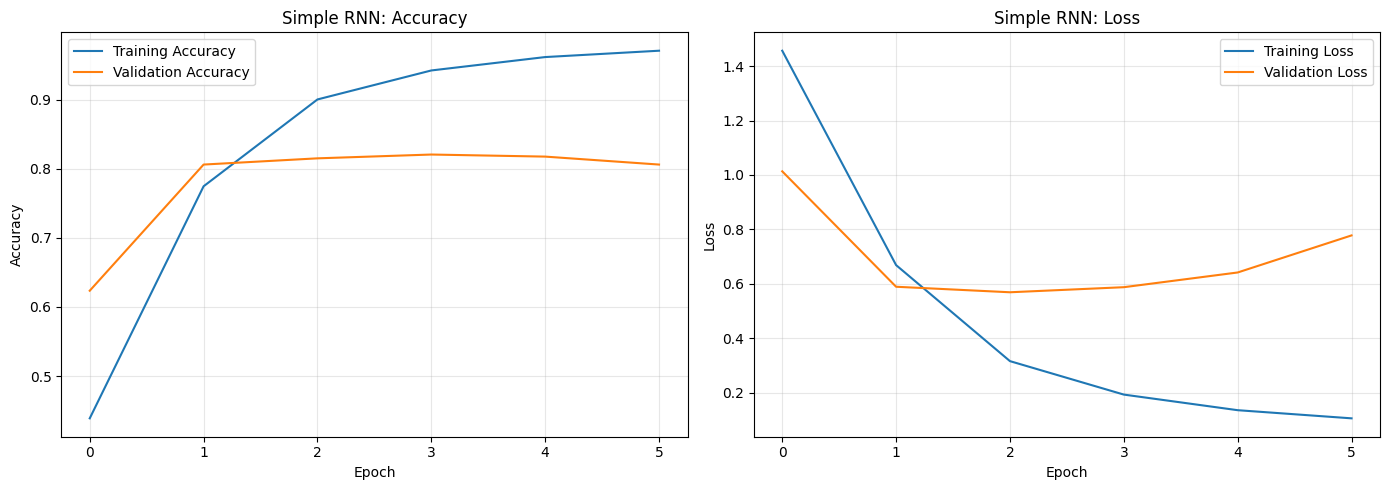

In [19]:

# ============================================
# CELL 15: PLOT TRAINING AND VALIDATION CURVES
# ============================================

# Create two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training and validation accuracy.
axes[0].plot(
    rnn_history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    rnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Simple RNN: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot training and validation loss.
axes[1].plot(
    rnn_history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    rnn_history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Simple RNN: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [20]:

# ============================================
# CELL 16: EVALUATE SIMPLE RNN
# ============================================

# Evaluate the restored best model on unseen test examples.
test_loss, test_accuracy = rnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Predict a probability distribution over the six emotions.
y_test_prob = rnn_model.predict(
    X_test,
    batch_size=64,
    verbose=0
)

# Convert predicted probabilities into emotion class IDs.
y_test_pred = np.argmax(y_test_prob, axis=1)

# Calculate macro F1-score.
# Each emotion contributes equally, regardless of its frequency.
rnn_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1-score: {rnn_macro_f1:.4f}")

# Show precision, recall and F1-score for every emotion.
print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_test_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=label_names,
        zero_division=0
    )
)


Test Loss: 0.5482
Test Accuracy: 0.8200
Test Macro F1-score: 0.7178

Classification Report:

              precision    recall  f1-score   support

     sadness       0.88      0.89      0.89       581
         joy       0.90      0.86      0.88       695
        love       0.59      0.74      0.66       159
       anger       0.82      0.81      0.82       275
        fear       0.74      0.72      0.73       224
    surprise       0.36      0.32      0.34        66

    accuracy                           0.82      2000
   macro avg       0.71      0.72      0.72      2000
weighted avg       0.82      0.82      0.82      2000



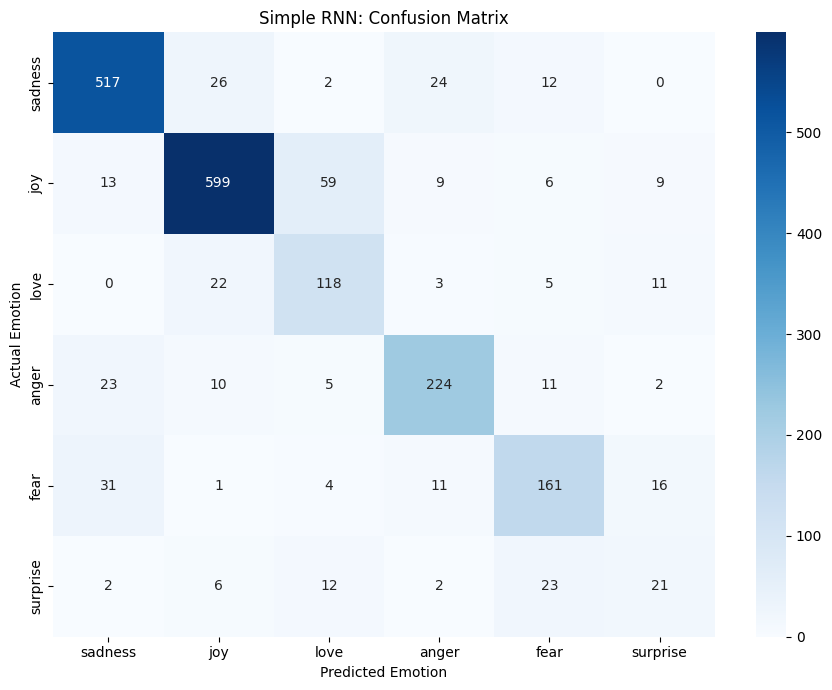

In [21]:

# ============================================
# CELL 17: CONFUSION MATRIX
# ============================================

# Compare actual emotion labels with predicted labels.
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=np.arange(NUM_CLASSES)
)

# Visualize the confusion matrix.
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.title("Simple RNN: Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [22]:

# ============================================
# CELL 18: STORE SIMPLE RNN RESULTS
# ============================================

# Create a dictionary to store the metrics for this model.
# Later, we will append the LSTM and GRU results.
results = [
    {
        "Model": "Simple RNN",
        "Test Accuracy": float(test_accuracy),
        "Macro F1": float(rnn_macro_f1),
        "Test Loss": float(test_loss),
        "Training Time (seconds)": float(rnn_training_time),
        "Parameters": int(rnn_model.count_params())
    }
]

# Display the current comparison table.
results_df = pd.DataFrame(results)

display(results_df.round(4))

# Save the trained model in Keras format.
rnn_model.save("simple_rnn_emotion.keras")

print("Simple RNN model saved successfully!")


,Model,Test Accuracy,Macro F1,Test Loss,Training Time (seconds),Parameters
0,Simple RNN,0.82,0.7178,0.5482,32.2879,1010950


Simple RNN model saved successfully!


In [23]:

# ============================================
# CELL 19: BUILD THE LSTM MODEL
# ============================================

lstm_model = keras.Sequential([

    # Accept sequences containing 50 integer token IDs.
    layers.Input(
        shape=(MAX_SEQUENCE_LENGTH,),
        dtype="int32"
    ),

    # Convert each token ID into a trainable 100-dimensional vector.
    # Padding tokens (ID 0) are masked.
    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=100,
        mask_zero=True,
        name="embedding"
    ),

    # Process the sequence using 64 LSTM units.
    # Each unit maintains a hidden state and a cell state.
    # return_sequences=False returns the final output only.
    layers.LSTM(
        units=64,
        return_sequences=False,
        name="lstm"
    ),

    # Drop 30% of activations during training to reduce overfitting.
    layers.Dropout(
        0.3,
        name="dropout"
    ),

    # Output probabilities for the six emotion categories.
    layers.Dense(
        units=NUM_CLASSES,
        activation="softmax",
        name="emotion_output"
    )
])

# Display the model architecture and trainable parameter counts.
lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_output (Dense)          │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,042,630 (3.98 MB)

 Trainable params: 1,042,630 (3.98 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:

# ============================================
# CELL 20: COMPILE THE LSTM MODEL
# ============================================

lstm_model.compile(

    # Use Adam with the same learning rate as the Simple RNN.
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Our target labels are integers from 0 to 5.
    loss="sparse_categorical_crossentropy",

    # Track classification accuracy.
    metrics=["accuracy"]
)

print("LSTM model compiled successfully!")


LSTM model compiled successfully!


In [25]:

# ============================================
# CELL 21: TRAIN THE LSTM MODEL
# ============================================

# Stop if validation loss fails to improve for three epochs.
lstm_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Record the start time.
start_time = time.perf_counter()

# Train the LSTM using the same training and validation data.
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=15,
    validation_data=(X_val, y_val),
    callbacks=[lstm_early_stopping],
    verbose=1
)

# Record the total training duration.
lstm_training_time = time.perf_counter() - start_time

print(f"\nLSTM training time: {lstm_training_time:.2f} seconds")
print(f"Epochs completed: {len(lstm_history.history['loss'])}")


Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 12s 43ms/step - accuracy: 0.4895 - loss: 1.3062 - val_accuracy: 0.7345 - val_loss: 0.7733
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.8490 - loss: 0.4617 - val_accuracy: 0.8890 - val_loss: 0.3266
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.9391 - loss: 0.1914 - val_accuracy: 0.9075 - val_loss: 0.2741
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.9636 - loss: 0.1136 - val_accuracy: 0.9120 - val_loss: 0.2832
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.9719 - loss: 0.0892 - val_accuracy: 0.9120 - val_loss: 0.2595
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9771 - loss: 0.0744 - val_accuracy: 0.9005 - val_loss: 0.3784
Epoch 7/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.9797 - loss: 0.0652 - val_accuracy: 0.9160 - val_loss: 0.2930
Epoch 8/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.9854 - loss: 0.0460 - 

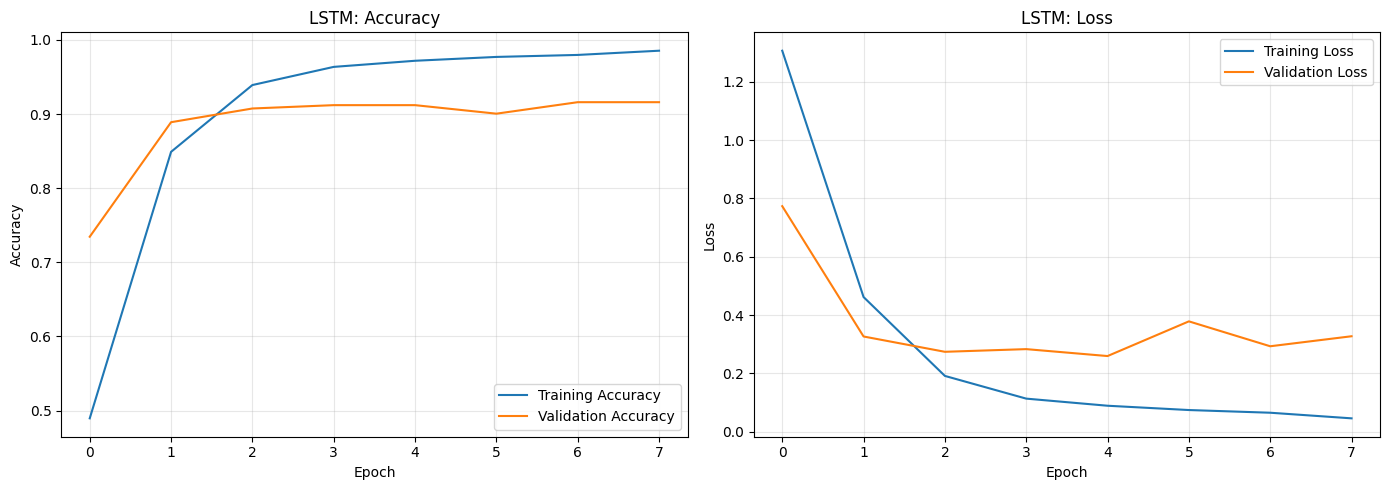

In [26]:

# ============================================
# CELL 22: PLOT LSTM TRAINING CURVES
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Compare training and validation accuracy.
axes[0].plot(
    lstm_history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    lstm_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("LSTM: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Compare training and validation loss.
axes[1].plot(
    lstm_history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("LSTM: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:

# ============================================
# CELL 23: EVALUATE THE LSTM MODEL
# ============================================

# Evaluate the best restored model on the held-out test set.
lstm_test_loss, lstm_test_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Generate predicted probabilities for all test examples.
lstm_test_prob = lstm_model.predict(
    X_test,
    batch_size=64,
    verbose=0
)

# Select the class with the highest predicted probability.
lstm_test_pred = np.argmax(
    lstm_test_prob,
    axis=1
)

# Calculate the macro F1-score across all six emotions.
lstm_macro_f1 = f1_score(
    y_test,
    lstm_test_pred,
    average="macro"
)

print(f"LSTM Test Loss: {lstm_test_loss:.4f}")
print(f"LSTM Test Accuracy: {lstm_test_accuracy:.4f}")
print(f"LSTM Macro F1-score: {lstm_macro_f1:.4f}")

# Show performance separately for each emotion.
print("\nLSTM Classification Report:\n")

print(
    classification_report(
        y_test,
        lstm_test_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=label_names,
        zero_division=0
    )
)


LSTM Test Loss: 0.2678
LSTM Test Accuracy: 0.9105
LSTM Macro F1-score: 0.8694

LSTM Classification Report:

              precision    recall  f1-score   support

     sadness       0.98      0.92      0.95       581
         joy       0.95      0.92      0.93       695
        love       0.70      0.90      0.79       159
       anger       0.91      0.93      0.92       275
        fear       0.88      0.89      0.88       224
    surprise       0.70      0.79      0.74        66

    accuracy                           0.91      2000
   macro avg       0.85      0.89      0.87      2000
weighted avg       0.92      0.91      0.91      2000



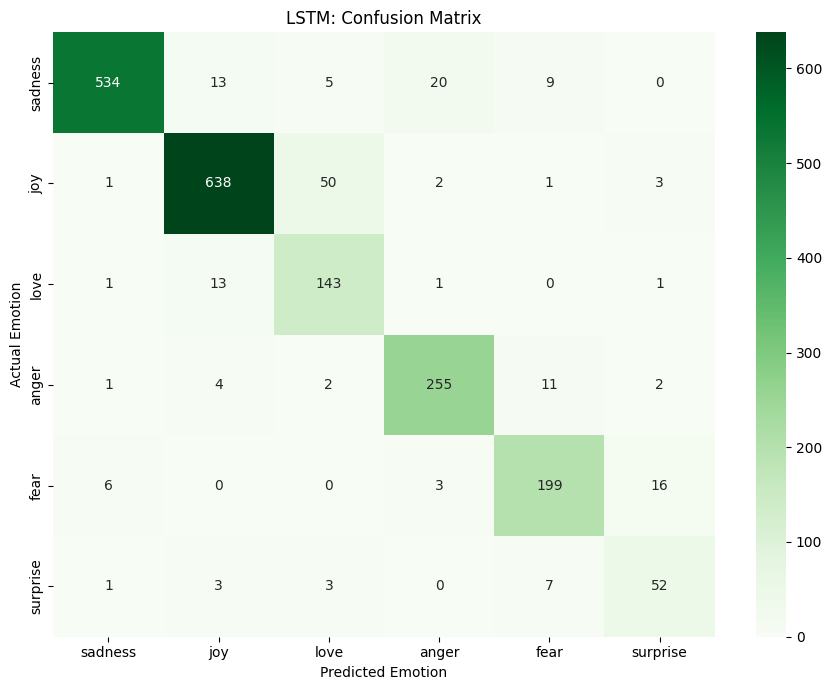

In [28]:

# ============================================
# CELL 24: LSTM CONFUSION MATRIX
# ============================================

# Compare actual labels with the LSTM's predicted labels.
lstm_cm = confusion_matrix(
    y_test,
    lstm_test_pred,
    labels=np.arange(NUM_CLASSES)
)

# Visualize classification errors.
plt.figure(figsize=(9, 7))

sns.heatmap(
    lstm_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.title("LSTM: Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [29]:

# ============================================
# CELL 25: STORE LSTM RESULTS
# ============================================

# Add the LSTM's test metrics and computational cost.
results.append({
    "Model": "LSTM",
    "Test Accuracy": float(lstm_test_accuracy),
    "Macro F1": float(lstm_macro_f1),
    "Test Loss": float(lstm_test_loss),
    "Training Time (seconds)": float(lstm_training_time),
    "Parameters": int(lstm_model.count_params())
})

# Display the results collected so far.
results_df = pd.DataFrame(results)

display(results_df.round(4))

# Save the trained LSTM model.
lstm_model.save("lstm_emotion.keras")

print("LSTM model saved successfully!")


,Model,Test Accuracy,Macro F1,Test Loss,Training Time (seconds),Parameters
0,Simple RNN,0.8200,0.7178,0.5482,32.2879,1010950
1,LSTM,0.9105,0.8694,0.2678,94.1674,1042630


LSTM model saved successfully!


In [30]:

# ============================================
# CELL 26: BUILD THE GRU MODEL
# ============================================

gru_model = keras.Sequential([

    # Accept sequences containing 50 integer token IDs.
    layers.Input(
        shape=(MAX_SEQUENCE_LENGTH,),
        dtype="int32"
    ),

    # Convert each token ID into a trainable 100-dimensional vector.
    # mask_zero=True ensures padding tokens are ignored by the GRU.
    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=100,
        mask_zero=True,
        name="embedding"
    ),

    # Process the sentence using 64 GRU units.
    # Each unit maintains a hidden state across time steps.
    # return_sequences=False returns the final output only.
    layers.GRU(
        units=64,
        return_sequences=False,
        name="gru"
    ),

    # Apply dropout during training to help reduce overfitting.
    layers.Dropout(
        0.3,
        name="dropout"
    ),

    # Produce one probability for each of the six emotions.
    layers.Dense(
        units=NUM_CLASSES,
        activation="softmax",
        name="emotion_output"
    )
])

# Display the architecture and parameter counts.
gru_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        31,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion_output (Dense)          │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,032,262 (3.94 MB)

 Trainable params: 1,032,262 (3.94 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:

# ============================================
# CELL 27: COMPILE THE GRU MODEL
# ============================================

gru_model.compile(

    # Adam optimizer with the same learning rate.
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Suitable for integer-encoded multiclass labels.
    loss="sparse_categorical_crossentropy",

    # Track classification accuracy during training.
    metrics=["accuracy"]
)

print("GRU model compiled successfully!")


GRU model compiled successfully!


In [32]:

# ============================================
# CELL 27: COMPILE THE GRU MODEL
# ============================================

gru_model.compile(

    # Adam optimizer with the same learning rate.
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    # Suitable for integer-encoded multiclass labels.
    loss="sparse_categorical_crossentropy",

    # Track classification accuracy during training.
    metrics=["accuracy"]
)

print("GRU model compiled successfully!")


GRU model compiled successfully!


In [33]:

# ============================================
# CELL 28: TRAIN THE GRU MODEL
# ============================================

# Stop training when validation loss stops improving.
gru_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Record the start time for measuring training duration.
start_time = time.perf_counter()

# Train on the same data and use the same settings
# as the Simple RNN and LSTM experiments.
gru_history = gru_model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=15,
    validation_data=(X_val, y_val),
    callbacks=[gru_early_stopping],
    verbose=1
)

# Calculate the total training duration.
gru_training_time = time.perf_counter() - start_time

print(f"\nGRU training time: {gru_training_time:.2f} seconds")
print(f"Epochs completed: {len(gru_history.history['loss'])}")


Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.4783 - loss: 1.3319 - val_accuracy: 0.7845 - val_loss: 0.6912
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.8922 - loss: 0.3563 - val_accuracy: 0.9160 - val_loss: 0.2597
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - accuracy: 0.9486 - loss: 0.1410 - val_accuracy: 0.9275 - val_loss: 0.2072
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9626 - loss: 0.0959 - val_accuracy: 0.9265 - val_loss: 0.2139
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9711 - loss: 0.0734 - val_accuracy: 0.9270 - val_loss: 0.2301
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9753 - loss: 0.0673 - val_accuracy: 0.9260 - val_loss: 0.2213
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.

GRU training time: 55.84 seconds
Epochs completed: 6


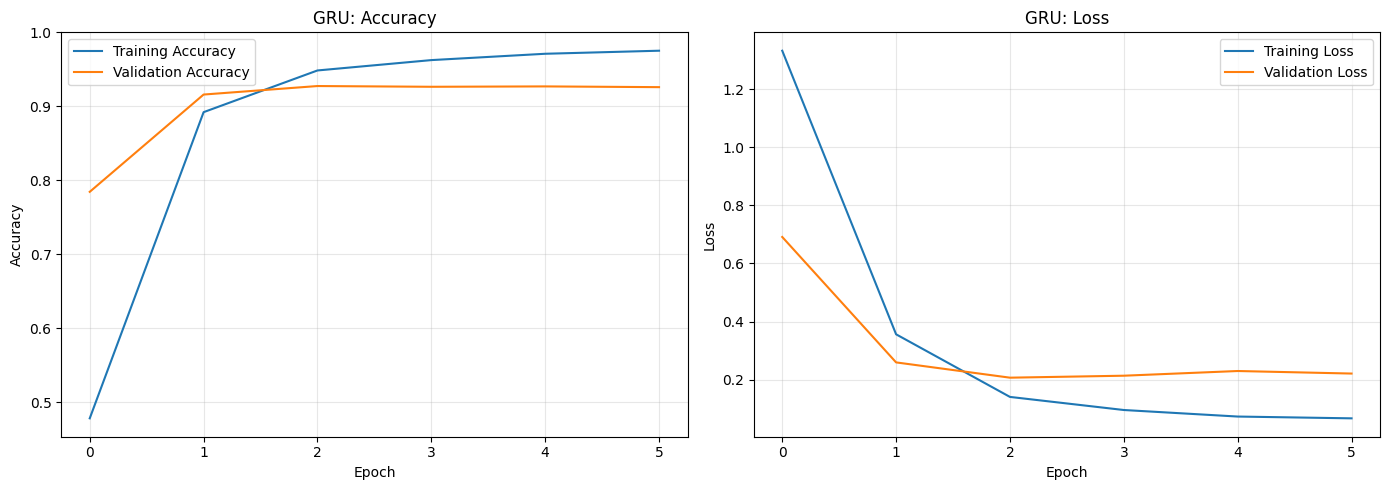

In [34]:

# ============================================
# CELL 29: PLOT GRU TRAINING CURVES
# ============================================

# Create separate plots for accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training and validation accuracy.
axes[0].plot(
    gru_history.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    gru_history.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("GRU: Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot training and validation loss.
axes[1].plot(
    gru_history.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    gru_history.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("GRU: Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [35]:

# ============================================
# CELL 30: EVALUATE THE GRU MODEL
# ============================================

# Evaluate the trained model on unseen test data.
gru_test_loss, gru_test_accuracy = gru_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Generate a probability distribution for each test example.
gru_test_prob = gru_model.predict(
    X_test,
    batch_size=64,
    verbose=0
)

# Convert predicted probabilities to emotion class IDs.
gru_test_pred = np.argmax(
    gru_test_prob,
    axis=1
)

# Calculate macro F1-score across all six emotion classes.
gru_macro_f1 = f1_score(
    y_test,
    gru_test_pred,
    average="macro"
)

# Display the final test metrics.
print(f"GRU Test Loss: {gru_test_loss:.4f}")
print(f"GRU Test Accuracy: {gru_test_accuracy:.4f}")
print(f"GRU Macro F1-score: {gru_macro_f1:.4f}")

# Display precision, recall and F1-score for every emotion.
print("\nGRU Classification Report:\n")

print(
    classification_report(
        y_test,
        gru_test_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=label_names,
        zero_division=0
    )
)


GRU Test Loss: 0.1940
GRU Test Accuracy: 0.9300
GRU Macro F1-score: 0.8899

GRU Classification Report:

              precision    recall  f1-score   support

     sadness       0.97      0.97      0.97       581
         joy       0.95      0.94      0.95       695
        love       0.83      0.86      0.84       159
       anger       0.92      0.93      0.93       275
        fear       0.92      0.88      0.90       224
    surprise       0.72      0.79      0.75        66

    accuracy                           0.93      2000
   macro avg       0.88      0.90      0.89      2000
weighted avg       0.93      0.93      0.93      2000



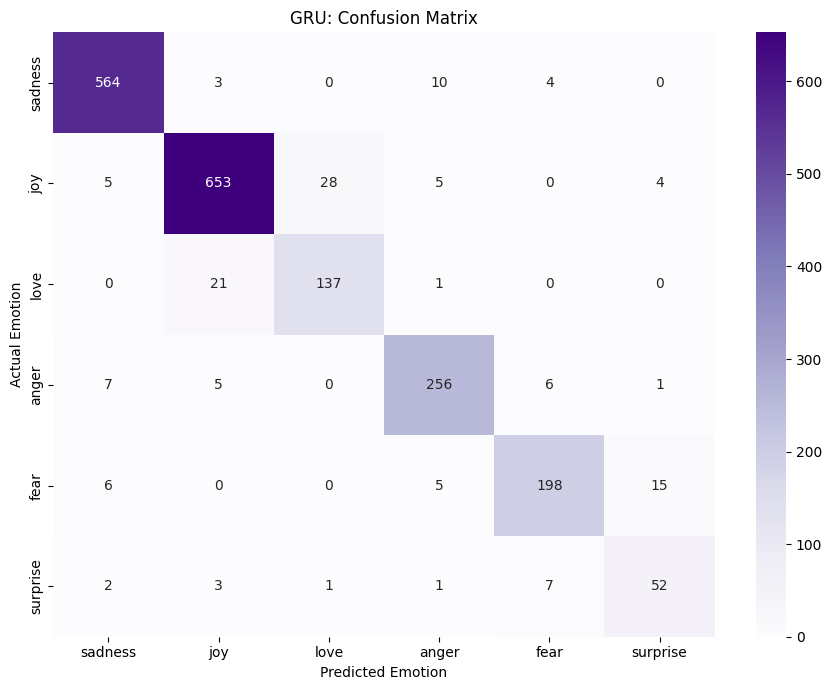

In [36]:

# ============================================
# CELL 31: GRU CONFUSION MATRIX
# ============================================

# Compare actual emotions against GRU predictions.
gru_cm = confusion_matrix(
    y_test,
    gru_test_pred,
    labels=np.arange(NUM_CLASSES)
)

# Plot the confusion matrix.
plt.figure(figsize=(9, 7))

sns.heatmap(
    gru_cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.title("GRU: Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()


In [37]:

# ============================================
# CELL 32: STORE GRU RESULTS
# ============================================

# Add GRU performance and computational cost.
results.append({
    "Model": "GRU",
    "Test Accuracy": float(gru_test_accuracy),
    "Macro F1": float(gru_macro_f1),
    "Test Loss": float(gru_test_loss),
    "Training Time (seconds)": float(gru_training_time),
    "Parameters": int(gru_model.count_params())
})

# Display all three models' results collected so far.
results_df = pd.DataFrame(results)

display(results_df.round(4))

# Save the trained GRU model.
gru_model.save("gru_emotion.keras")

print("GRU model saved successfully!")


,Model,Test Accuracy,Macro F1,Test Loss,Training Time (seconds),Parameters
0,Simple RNN,0.8200,0.7178,0.5482,32.2879,1010950
1,LSTM,0.9105,0.8694,0.2678,94.1674,1042630
2,GRU,0.9300,0.8899,0.1940,55.8432,1032262


GRU model saved successfully!


In [38]:

# ============================================
# CELL 33: COMPARE ALL THREE MODELS
# ============================================

# Convert the collected results into a DataFrame.
comparison_df = pd.DataFrame(results)

# Sort models by macro F1-score, from highest to lowest.
# Macro F1 gives equal importance to all six emotion classes.
comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

# Display all metrics rounded to four decimal places.
display(comparison_df.round(4))

# Identify the model with the highest macro F1-score.
best_model_name = comparison_df.loc[0, "Model"]

print("Best model by test macro F1-score:", best_model_name)


,Model,Test Accuracy,Macro F1,Test Loss,Training Time (seconds),Parameters
0,GRU,0.9300,0.8899,0.1940,55.8432,1032262
1,LSTM,0.9105,0.8694,0.2678,94.1674,1042630
2,Simple RNN,0.8200,0.7178,0.5482,32.2879,1010950


Best model by test macro F1-score: GRU


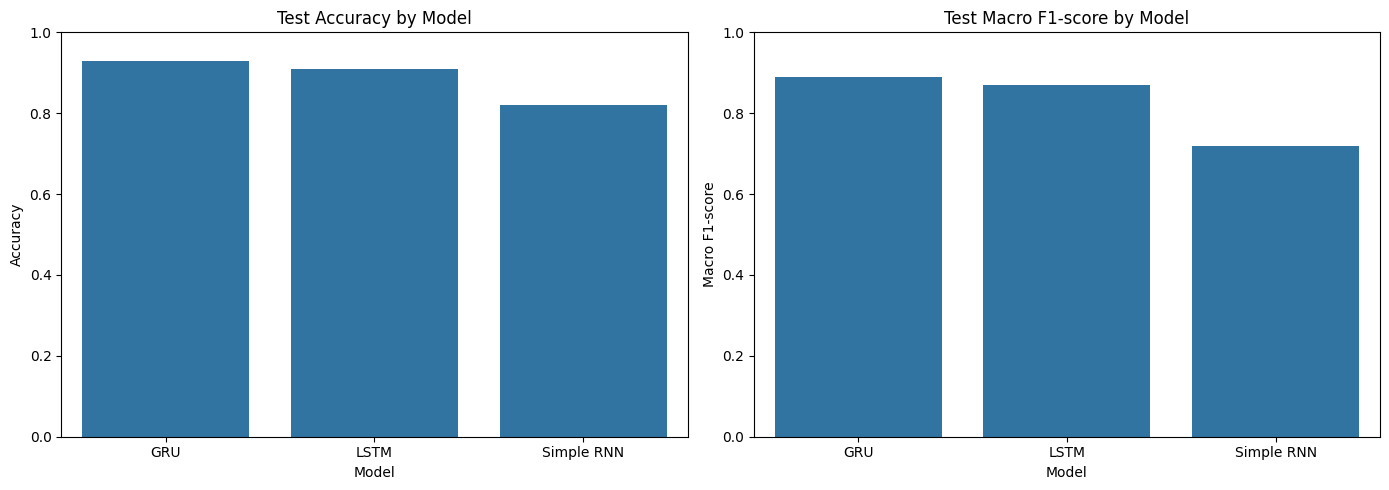

In [39]:

# ============================================
# CELL 34: MODEL PERFORMANCE COMPARISON
# ============================================

# Create a figure with two comparison charts.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Compare test accuracy.
sns.barplot(
    data=comparison_df,
    x="Model",
    y="Test Accuracy",
    ax=axes[0]
)

axes[0].set_title("Test Accuracy by Model")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1)

# Compare test macro F1-score.
sns.barplot(
    data=comparison_df,
    x="Model",
    y="Macro F1",
    ax=axes[1]
)

axes[1].set_title("Test Macro F1-score by Model")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Macro F1-score")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()


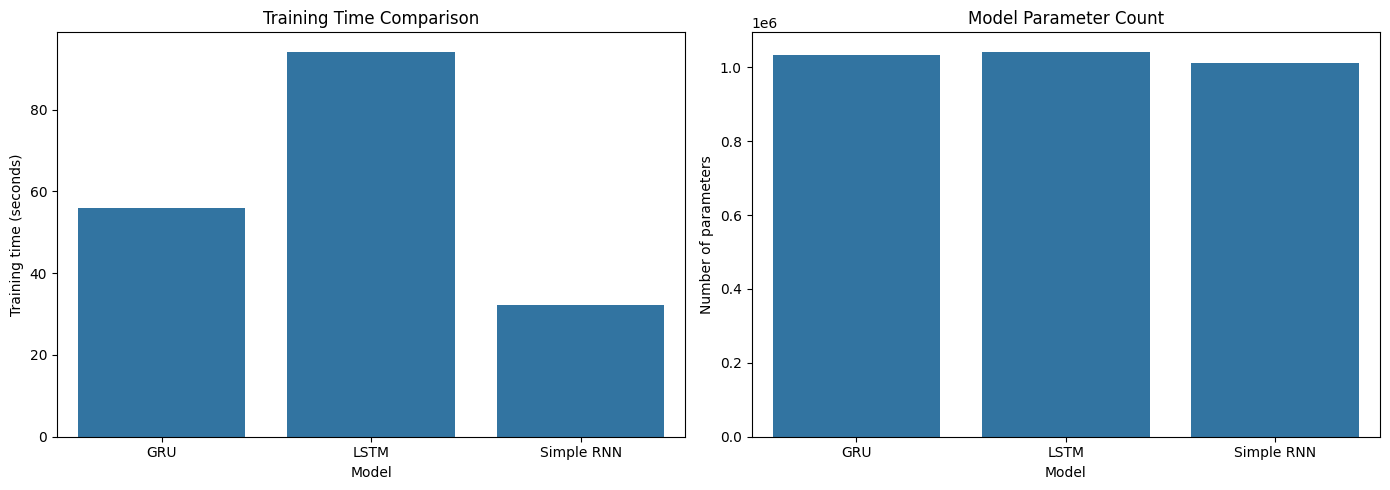

,Model,Training Time (seconds),Parameters
0,GRU,55.84,1032262
1,LSTM,94.17,1042630
2,Simple RNN,32.29,1010950


In [40]:

# ============================================
# CELL 35: COMPARE COMPUTATIONAL EFFICIENCY
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Compare measured training time.
sns.barplot(
    data=comparison_df,
    x="Model",
    y="Training Time (seconds)",
    ax=axes[0]
)

axes[0].set_title("Training Time Comparison")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Training time (seconds)")

# Compare trainable and non-trainable parameter counts.
sns.barplot(
    data=comparison_df,
    x="Model",
    y="Parameters",
    ax=axes[1]
)

axes[1].set_title("Model Parameter Count")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Number of parameters")

plt.tight_layout()
plt.show()

# Display the efficiency metrics.
display(
    comparison_df[
        ["Model", "Training Time (seconds)", "Parameters"]
    ].round(2)
)


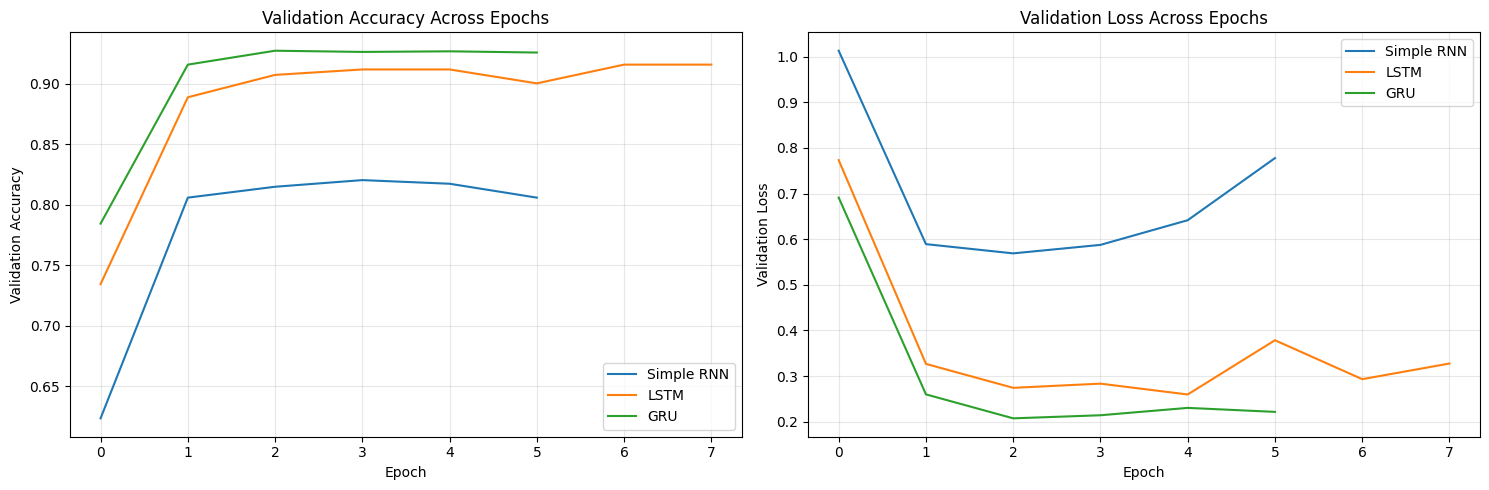

In [41]:

# ============================================
# CELL 36: COMPARE LEARNING CURVES
# ============================================

# Keep the histories paired with their model names.
histories = {
    "Simple RNN": rnn_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot validation accuracy for all three architectures.
for model_name, history in histories.items():
    axes[0].plot(
        history.history["val_accuracy"],
        label=model_name
    )

axes[0].set_title("Validation Accuracy Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot validation loss for all three architectures.
for model_name, history in histories.items():
    axes[1].plot(
        history.history["val_loss"],
        label=model_name
    )

axes[1].set_title("Validation Loss Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Model,GRU,LSTM,Simple RNN
Emotion,,,
anger,0.9259,0.9173,0.8175
fear,0.9021,0.8825,0.7285
joy,0.9464,0.9341,0.8815
love,0.8431,0.7901,0.6574
sadness,0.9682,0.9493,0.8860
surprise,0.7536,0.7429,0.3360


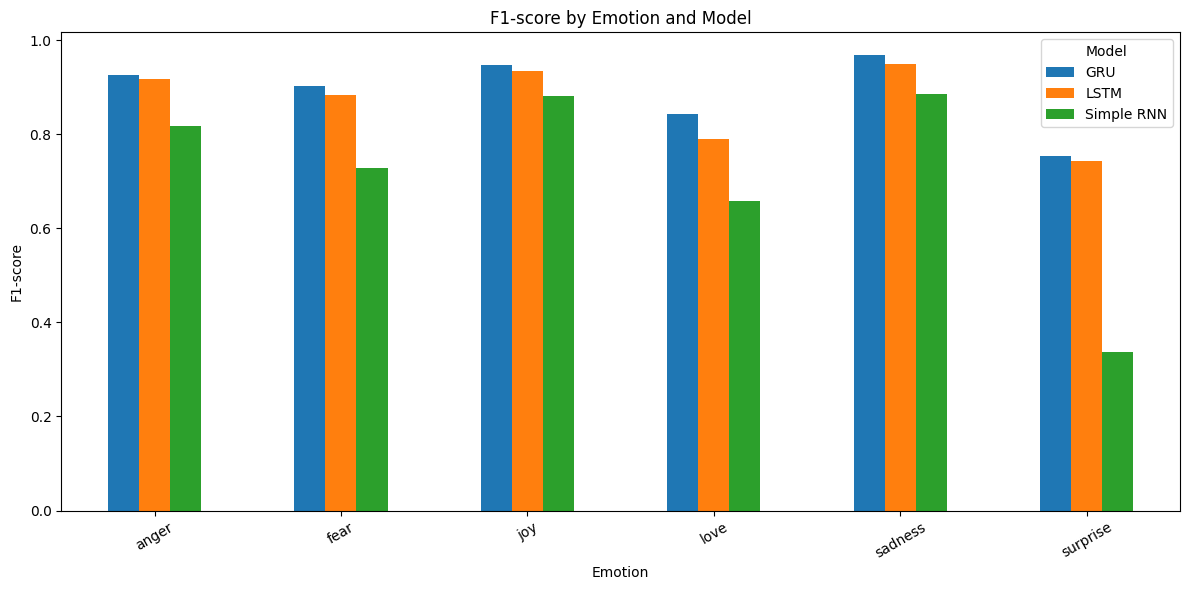

In [42]:

# ============================================
# CELL 37: PER-EMOTION F1 COMPARISON
# ============================================

# Store each model's test predictions in one dictionary.
predictions = {
    "Simple RNN": y_test_pred,
    "LSTM": lstm_test_pred,
    "GRU": gru_test_pred
}

# Calculate F1-score separately for each emotion.
per_emotion_results = []

for model_name, predictions_for_model in predictions.items():

    # Calculate one F1-score per emotion class.
    class_f1 = f1_score(
        y_test,
        predictions_for_model,
        labels=np.arange(NUM_CLASSES),
        average=None,
        zero_division=0
    )

    # Save each class's score for comparison.
    for emotion, score in zip(label_names, class_f1):
        per_emotion_results.append({
            "Model": model_name,
            "Emotion": emotion,
            "F1-score": score
        })

# Convert the results into a DataFrame.
per_emotion_df = pd.DataFrame(per_emotion_results)

# Pivot the table so each model becomes a separate column.
per_emotion_pivot = per_emotion_df.pivot(
    index="Emotion",
    columns="Model",
    values="F1-score"
)

display(per_emotion_pivot.round(4))

# Plot per-emotion performance for all three models.
per_emotion_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("F1-score by Emotion and Model")
plt.xlabel("Emotion")
plt.ylabel("F1-score")
plt.xticks(rotation=30)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [43]:

# ============================================
# CELL 38: FINAL EXPERIMENT SUMMARY
# ============================================

# Rank the models by test macro F1-score.
ranked_results = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

# Display the top-ranked model based on macro F1.
best_model = ranked_results.iloc[0]

print("=" * 55)
print("TEXT EMOTION DETECTION: EXPERIMENT SUMMARY")
print("=" * 55)

print("\nBest model by test macro F1:")
print(best_model["Model"])

print(f"\nTest accuracy: {best_model['Test Accuracy']:.4f}")
print(f"Test macro F1: {best_model['Macro F1']:.4f}")
print(f"Test loss: {best_model['Test Loss']:.4f}")
print(
    f"Training time: "
    f"{best_model['Training Time (seconds)']:.2f} seconds"
)
print(f"Parameter count: {best_model['Parameters']:,}")

print("\nComplete model ranking:")
print(
    ranked_results[
        ["Model", "Test Accuracy", "Macro F1",
         "Training Time (seconds)", "Parameters"]
    ].to_string(index=False)
)

print("\nInterpretation:")
print(
    "The model with the highest test macro F1 has the best "
    "measured balance of precision and recall across the "
    "six emotion classes in this experiment."
)
print(
    "Consider accuracy, training cost, per-emotion performance "
    "and run-to-run variability before choosing the final model."
)


TEXT EMOTION DETECTION: EXPERIMENT SUMMARY

Best model by test macro F1:
GRU

Test accuracy: 0.9300
Test macro F1: 0.8899
Test loss: 0.1940
Training time: 55.84 seconds
Parameter count: 1,032,262

Complete model ranking:
     Model  Test Accuracy  Macro F1  Training Time (seconds)  Parameters
       GRU         0.9300  0.889871                55.843246     1032262
      LSTM         0.9105  0.869352                94.167375     1042630
Simple RNN         0.8200  0.717828                32.287908     1010950

Interpretation:
The model with the highest test macro F1 has the best measured balance of precision and recall across the six emotion classes in this experiment.
Consider accuracy, training cost, per-emotion performance and run-to-run variability before choosing the final model.


In [44]:

# ============================================
# CELL 39: TEXT EMOTION PREDICTION FUNCTION
# ============================================

def predict_emotion(text):
    """
    Predict emotions for a single text using Simple RNN, LSTM and GRU.

    Parameters
    ----------
    text : str
        The sentence whose emotion we want to classify.

    Returns
    -------
    pandas.DataFrame
        Predicted emotion and probability from each model.
    """

    # Validate the input before passing it to the models.
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty text string.")

    # Convert the input into a batch containing one sentence.
    # The vectorizer uses the vocabulary learned in Step 2.
    input_sequence = text_vectorizer(
        tf.constant([text])
    )

    # Store the three trained models under readable names.
    models = {
        "Simple RNN": rnn_model,
        "LSTM": lstm_model,
        "GRU": gru_model
    }

    # Store one result for every model.
    predictions = []

    for model_name, model in models.items():

        # Predict probabilities for all six emotion classes.
        probabilities = model.predict(
            input_sequence,
            verbose=0
        )[0]

        # Find the class with the highest probability.
        predicted_class = int(np.argmax(probabilities))

        # Save the prediction and its probability.
        predictions.append({
            "Model": model_name,
            "Predicted Emotion": label_names[predicted_class],
            "Confidence (%)": float(
                probabilities[predicted_class] * 100
            )
        })

    # Return the results in a readable table.
    return pd.DataFrame(predictions)


In [45]:

# ============================================
# CELL 40: TEST CUSTOM SENTENCES
# ============================================

# Try a few sentences with different emotional meanings.
test_sentences = [
    "I am extremely happy with my new job.",
    "I feel sad because I miss my family.",
    "I am worried about my examination results.",
    "I am so angry about what happened today.",
    "I love spending time with my friends.",
    "Wow, I never expected to win this prize!"
]

# Run every sentence through all three models.
for sentence in test_sentences:

    print("\n" + "=" * 75)
    print("INPUT TEXT:", sentence)
    print("=" * 75)

    # Get predictions from RNN, LSTM and GRU.
    prediction_table = predict_emotion(sentence)

    # Display the predictions.
    display(prediction_table.round(2))



INPUT TEXT: I am extremely happy with my new job.


,Model,Predicted Emotion,Confidence (%)
0,Simple RNN,joy,67.38
1,LSTM,joy,76.67
2,GRU,joy,86.81



INPUT TEXT: I feel sad because I miss my family.


,Model,Predicted Emotion,Confidence (%)
0,Simple RNN,sadness,97.10
1,LSTM,sadness,83.82
2,GRU,sadness,99.66



INPUT TEXT: I am worried about my examination results.


...

,Model,Predicted Emotion,Confidence (%)
0,Simple RNN,anger,95.57
1,LSTM,anger,91.39
2,GRU,anger,93.81



INPUT TEXT: I love spending time with my friends.


,Model,Predicted Emotion,Confidence (%)
0,Simple RNN,love,45.47
1,LSTM,love,38.40
2,GRU,anger,54.45



INPUT TEXT: Wow, I never expected to win this prize!


,Model,Predicted Emotion,Confidence (%)
0,Simple RNN,joy,53.02
1,LSTM,love,52.76
2,GRU,love,28.33


In [46]:

# ============================================
# CELL 41: DISPLAY ALL EMOTION PROBABILITIES
# ============================================

def predict_emotion_probabilities(text):
    """
    Display the predicted probability of every emotion
    for each of the three models.
    """

    # Convert text to the same numerical representation used in training.
    input_sequence = text_vectorizer(
        tf.constant([text])
    )

    # Collect the probability distributions from all models.
    probability_results = {}

    models = {
        "Simple RNN": rnn_model,
        "LSTM": lstm_model,
        "GRU": gru_model
    }

    for model_name, model in models.items():

        # Obtain the six class probabilities.
        probabilities = model.predict(
            input_sequence,
            verbose=0
        )[0]

        probability_results[model_name] = probabilities

    # Organize results with emotions as rows and models as columns.
    probability_df = pd.DataFrame(
        probability_results,
        index=label_names
    )

    # Convert probabilities to percentages for readability.
    probability_df = probability_df * 100

    return probability_df.round(2)


# Try a sentence with potentially mixed emotional meaning.
sample_text = (
    "I was scared before the interview, "
    "but now I am happy that it went well."
)

display(predict_emotion_probabilities(sample_text))


,Simple RNN,LSTM,GRU
sadness,57.570000,0.390000,1.45
joy,18.309999,0.120000,11.69
love,1.810000,0.100000,14.29
anger,1.360000,0.580000,12.00
fear,7.950000,97.169998,48.34
surprise,13.000000,1.640000,12.22


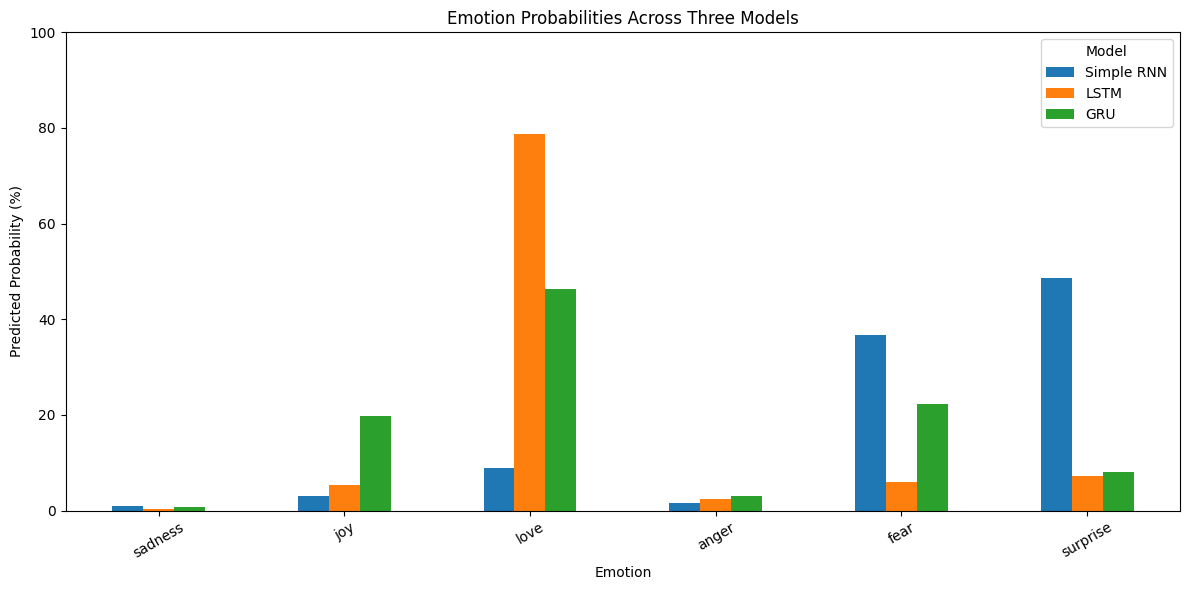

In [47]:

# ============================================
# CELL 42: PLOT EMOTION PROBABILITIES
# ============================================

# Generate predictions for one example sentence.
sample_text = "I am excited about my future, but nervous about the changes."

probability_df = predict_emotion_probabilities(sample_text)

# Plot the class probabilities for each model.
ax = probability_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Emotion Probabilities Across Three Models")
ax.set_xlabel("Emotion")
ax.set_ylabel("Predicted Probability (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=30)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [48]:

# ============================================
# CELL 43: PREPARE TEST PREDICTIONS
# ============================================

# Create a DataFrame containing the original text and true emotions.
error_df = pd.DataFrame({
    "Text": X_test_text,
    "Actual Label": y_test,
    "Actual Emotion": [
        label_names[label] for label in y_test
    ]
})

# Add each model's predicted class ID.
error_df["RNN Prediction"] = y_test_pred
error_df["LSTM Prediction"] = lstm_test_pred
error_df["GRU Prediction"] = gru_test_pred

# Convert predicted class IDs into readable emotion names.
error_df["RNN Emotion"] = [
    label_names[label] for label in y_test_pred
]

error_df["LSTM Emotion"] = [
    label_names[label] for label in lstm_test_pred
]

error_df["GRU Emotion"] = [
    label_names[label] for label in gru_test_pred
]

# Mark whether each model classified the example correctly.
error_df["RNN Correct"] = (
    error_df["RNN Prediction"] == error_df["Actual Label"]
)

error_df["LSTM Correct"] = (
    error_df["LSTM Prediction"] == error_df["Actual Label"]
)

error_df["GRU Correct"] = (
    error_df["GRU Prediction"] == error_df["Actual Label"]
)

# Show a few examples.
display(error_df.head())


,Text,Actual Label,Actual Emotion,RNN Prediction,LSTM Prediction,GRU Prediction,RNN Emotion,LSTM Emotion,GRU Emotion,RNN Correct,LSTM Correct,GRU Correct
0,im feeling rather rotten so im not very ambiti...,0,sadness,0,0,0,sadness,sadness,sadness,True,True,True
1,im updating my blog because i feel shitty,0,sadness,0,0,0,sadness,sadness,sadness,True,True,True
2,i never make her separate from me because i do...,0,sadness,0,0,0,sadness,sadness,sadness,True,True,True
3,i left with my bouquet of red and yellow tulip...,1,joy,1,1,1,joy,joy,joy,True,True,True
4,i was feeling a little vain when i did this one,0,sadness,0,0,0,sadness,sadness,sadness,True,True,True


In [49]:

# ============================================
# CELL 44: INSPECT MISCLASSIFIED EXAMPLES
# ============================================

# Count the incorrect predictions made by each model.
print("Incorrect predictions:")
print("Simple RNN:", (~error_df["RNN Correct"]).sum())
print("LSTM:", (~error_df["LSTM Correct"]).sum())
print("GRU:", (~error_df["GRU Correct"]).sum())

# Display examples where the Simple RNN was incorrect.
print("\nSimple RNN errors:")

display(
    error_df.loc[
        ~error_df["RNN Correct"],
        ["Text", "Actual Emotion", "RNN Emotion"]
    ].head(15)
)

# Display examples where the LSTM was incorrect.
print("\nLSTM errors:")

display(
    error_df.loc[
        ~error_df["LSTM Correct"],
        ["Text", "Actual Emotion", "LSTM Emotion"]
    ].head(15)
)

# Display examples where the GRU was incorrect.
print("\nGRU errors:")

display(
    error_df.loc[
        ~error_df["GRU Correct"],
        ["Text", "Actual Emotion", "GRU Emotion"]
    ].head(15)
)


Incorrect predictions:
Simple RNN: 360
LSTM: 179
GRU: 140

Simple RNN errors:


,Text,Actual Emotion,RNN Emotion
5,i cant walk into a shop anywhere where i do no...,fear,joy
12,i pay attention it deepens into a feeling of b...,fear,sadness
14,i find myself in the odd position of feeling s...,love,surprise
18,i feel just bcoz a fight we get mad to each ot...,anger,love
20,im not sure the feeling of loss will ever go a...,sadness,joy
22,i survey my own posts over the last few years ...,joy,fear
36,i feel very honoured to be included in a magzi...,joy,surprise
49,i was feeling pretty anxious all day but my fi...,fear,sadness
53,i can t stop the anxiety i feel when i m alone...,sadness,anger
59,i think about the things ive said and the stuf...,anger,joy



LSTM errors:


,Text,Actual Emotion,LSTM Emotion
6,i felt anger when at the end of a telephone call,anger,love
10,i don t feel particularly agitated,fear,anger
12,i pay attention it deepens into a feeling of b...,fear,sadness
20,im not sure the feeling of loss will ever go a...,sadness,love
62,i spent wandering around still kinda dazed and...,joy,love
93,i was feeling weird the other day and it went ...,fear,surprise
98,i feel my heart is tortured by what i have done,anger,fear
100,i feel needy but comfortable with it i feel vu...,sadness,fear
108,i looked at mabel this morning i named my left...,fear,surprise
121,made a wonderfull new friend,joy,anger



GRU errors:


,Text,Actual Emotion,GRU Emotion
12,i pay attention it deepens into a feeling of b...,fear,sadness
40,i feel if i completely hated things i d exerci...,anger,sadness
67,i feel a bit stressed even though all the thin...,anger,sadness
93,i was feeling weird the other day and it went ...,fear,surprise
108,i looked at mabel this morning i named my left...,fear,surprise
111,i feel is he generous,love,joy
121,made a wonderfull new friend,joy,anger
131,im feeling generous today heres one more you m...,love,joy
137,i actually feel agitated which led to a terrib...,anger,fear
152,i was so uncomfortable and feeling weird feeli...,surprise,fear


In [50]:

# ============================================
# CELL 45: FIND SHARED MODEL ERRORS
# ============================================

# Select examples incorrectly classified by every model.
all_models_wrong = error_df.loc[
    (~error_df["RNN Correct"])
    & (~error_df["LSTM Correct"])
    & (~error_df["GRU Correct"])
]

print("Examples misclassified by all three models:")
print("Count:", len(all_models_wrong))

# Display the true emotion and all three predictions.
display(
    all_models_wrong[
        [
            "Text",
            "Actual Emotion",
            "RNN Emotion",
            "LSTM Emotion",
            "GRU Emotion"
        ]
    ].head(20)
)

# Find examples where all three models make the same prediction.
# This includes both correct and incorrect predictions.
all_models_agree = error_df.loc[
    (error_df["RNN Prediction"] == error_df["LSTM Prediction"])
    & (error_df["LSTM Prediction"] == error_df["GRU Prediction"])
]

print("\nExamples where all models agree:", len(all_models_agree))

# Show examples where the models agree but are wrong.
shared_wrong_prediction = all_models_agree.loc[
    ~all_models_agree["RNN Correct"]
]

display(
    shared_wrong_prediction[
        ["Text", "Actual Emotion", "RNN Emotion"]
    ].head(15)
)


Examples misclassified by all three models:
Count: 63


,Text,Actual Emotion,RNN Emotion,LSTM Emotion,GRU Emotion
12,i pay attention it deepens into a feeling of b...,fear,sadness,sadness,sadness
108,i looked at mabel this morning i named my left...,fear,anger,surprise,surprise
121,made a wonderfull new friend,joy,sadness,anger,anger
137,i actually feel agitated which led to a terrib...,anger,sadness,fear,fear
229,i am truly unfortunate the majority of the tim...,fear,sadness,sadness,sadness
262,i realized what i am passionate about helping ...,joy,love,love,love
265,i feel so blessed and honored that we get to b...,love,joy,joy,joy
314,i will nolonger tell anybody how i feel or wha...,sadness,anger,anger,anger
335,i believe that feeling accepted in a non judge...,joy,love,love,love
353,i could feel his breath on me and smell the sw...,joy,love,love,love



Examples where all models agree: 1603


,Text,Actual Emotion,RNN Emotion
12,i pay attention it deepens into a feeling of b...,fear,sadness
229,i am truly unfortunate the majority of the tim...,fear,sadness
262,i realized what i am passionate about helping ...,joy,love
265,i feel so blessed and honored that we get to b...,love,joy
314,i will nolonger tell anybody how i feel or wha...,sadness,anger
335,i believe that feeling accepted in a non judge...,joy,love
353,i could feel his breath on me and smell the sw...,joy,love
415,i loved the feeling i got during an amazing sl...,joy,surprise
426,i feel unprotected a class post count link hre...,sadness,fear
457,i cant do strappy shoes at work i just feel we...,fear,surprise


In [51]:

# ============================================
# CELL 46: ANALYZE COMMON CONFUSION PAIRS
# ============================================

def get_confusion_pairs(y_true, y_pred, emotion_names):
    """
    Return the most common incorrect actual-predicted emotion pairs.
    """

    # Build the confusion matrix using the same class order.
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(emotion_names))
    )

    # Convert non-diagonal confusion matrix cells into records.
    # Diagonal cells represent correct predictions and are excluded.
    pairs = []

    for actual_id in range(len(emotion_names)):
        for predicted_id in range(len(emotion_names)):

            if actual_id != predicted_id and cm[actual_id, predicted_id] > 0:
                pairs.append({
                    "Actual Emotion": emotion_names[actual_id],
                    "Predicted Emotion": emotion_names[predicted_id],
                    "Number of Errors": int(cm[actual_id, predicted_id])
                })

    # Sort from most common confusion to least common.
    return pd.DataFrame(pairs).sort_values(
        "Number of Errors",
        ascending=False
    ).reset_index(drop=True)


# Analyze errors for each architecture.
for model_name, model_predictions in predictions.items():

    print(f"\nMost common confusion pairs: {model_name}")

    confusion_pairs = get_confusion_pairs(
        y_test,
        model_predictions,
        label_names
    )

    display(confusion_pairs.head(10))



Most common confusion pairs: Simple RNN


,Actual Emotion,Predicted Emotion,Number of Errors
0,joy,love,59
1,fear,sadness,31
2,sadness,joy,26
3,sadness,anger,24
4,anger,sadness,23
5,surprise,fear,23
6,love,joy,22
7,fear,surprise,16
8,joy,sadness,13
9,sadness,fear,12



Most common confusion pairs: LSTM


,Actual Emotion,Predicted Emotion,Number of Errors
0,joy,love,50
1,sadness,anger,20
2,fear,surprise,16
3,love,joy,13
4,sadness,joy,13
5,anger,fear,11
6,sadness,fear,9
7,surprise,fear,7
8,fear,sadness,6
9,sadness,love,5



Most common confusion pairs: GRU


,Actual Emotion,Predicted Emotion,Number of Errors
0,joy,love,28
1,love,joy,21
2,fear,surprise,15
3,sadness,anger,10
4,surprise,fear,7
5,anger,sadness,7
6,anger,fear,6
7,fear,sadness,6
8,joy,sadness,5
9,fear,anger,5


In [52]:

# ============================================
# CELL 47: MANUAL ERROR ANALYSIS
# ============================================

# These are diagnostic examples, not part of the test dataset.
# Their expected labels are subjective and should not be treated
# as an authoritative benchmark.
diagnostic_sentences = [
    "I am happy about the result.",
    "I am not happy about the result.",
    "I was afraid, but now I feel relieved.",
    "I miss my family and feel lonely.",
    "I love this surprise!",
    "Great, another problem to deal with.",
    "I thought I would fail, but I passed.",
    "I am disappointed that my friend is leaving."
]

for sentence in diagnostic_sentences:

    print("\n" + "=" * 75)
    print("TEXT:", sentence)
    print("=" * 75)

    # Predict the probability of every emotion using each model.
    probability_df = predict_emotion_probabilities(sentence)

    # Display all six emotion probabilities.
    display(probability_df)



TEXT: I am happy about the result.


,Simple RNN,LSTM,GRU
sadness,3.980000,1.940000,3.840000
joy,85.910004,87.260002,77.790001
love,2.370000,8.170000,8.710000
anger,7.170000,1.780000,6.860000
fear,0.300000,0.450000,1.060000
surprise,0.270000,0.400000,1.740000



TEXT: I am not happy about the result.


,Simple RNN,LSTM,GRU
sadness,3.590000,2.020000,4.18
joy,79.910004,83.010002,72.57
love,5.310000,11.670000,11.23
anger,10.650000,2.130000,7.99
fear,0.250000,0.600000,1.58
surprise,0.280000,0.560000,2.44



TEXT: I was afraid, but now I feel relieved.


...

,Simple RNN,LSTM,GRU
sadness,4.460000,3.350000,3.180000
joy,32.709999,19.950001,13.370000
love,7.380000,48.840000,12.470000
anger,46.980000,11.710000,45.470001
fear,4.510000,6.160000,11.090000
surprise,3.950000,9.990000,14.430000



TEXT: I thought I would fail, but I passed.


,Simple RNN,LSTM,GRU
sadness,64.660004,87.080002,39.599998
joy,2.110000,1.480000,2.970000
love,0.080000,1.330000,2.100000
anger,32.049999,6.870000,38.599998
fear,0.970000,2.200000,13.140000
surprise,0.130000,1.030000,3.590000



TEXT: I am disappointed that my friend is leaving.


,Simple RNN,LSTM,GRU
sadness,95.559998,91.239998,88.739998
joy,0.110000,1.080000,0.090000
love,0.010000,0.340000,0.030000
anger,1.970000,4.930000,10.310000
fear,2.290000,2.160000,0.800000
surprise,0.060000,0.270000,0.030000


,Model,Correct Predictions,Incorrect Predictions,Error Rate (%)
0,Simple RNN,1640,360,18.00
1,LSTM,1821,179,8.95
2,GRU,1860,140,7.00


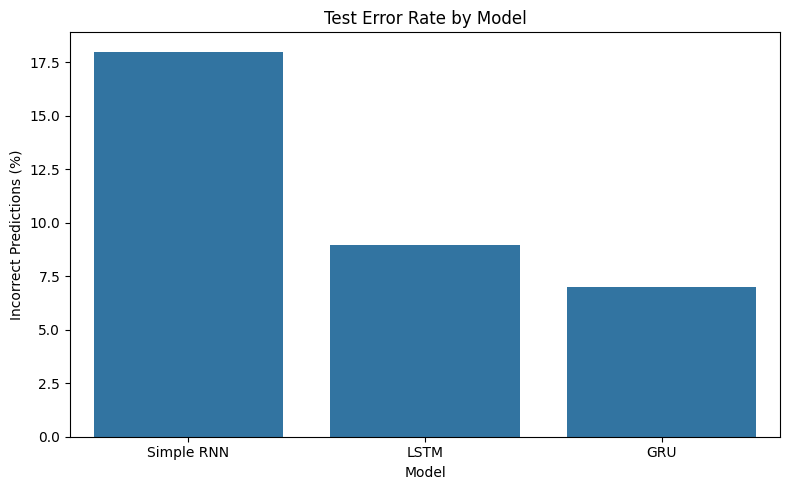

In [53]:

# ============================================
# CELL 48: COMPARE ERROR RATES
# ============================================

# Calculate the percentage of incorrect test predictions per model.
error_summary = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM", "GRU"],
    "Correct Predictions": [
        int(error_df["RNN Correct"].sum()),
        int(error_df["LSTM Correct"].sum()),
        int(error_df["GRU Correct"].sum())
    ],
    "Incorrect Predictions": [
        int((~error_df["RNN Correct"]).sum()),
        int((~error_df["LSTM Correct"]).sum()),
        int((~error_df["GRU Correct"]).sum())
    ]
})

# Calculate the error rate as a percentage.
error_summary["Error Rate (%)"] = (
    error_summary["Incorrect Predictions"]
    / len(error_df)
    * 100
)

display(error_summary.round(2))

# Visualize the error rates.
plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_summary,
    x="Model",
    y="Error Rate (%)"
)

plt.title("Test Error Rate by Model")
plt.xlabel("Model")
plt.ylabel("Incorrect Predictions (%)")
plt.tight_layout()
plt.show()


In [54]:

# ============================================
# CELL 49: SAVE THE TEXT PREPROCESSING PIPELINE
# ============================================

# Create a model that accepts raw text and returns token IDs.
# The existing text_vectorizer retains its learned vocabulary.
preprocessing_model = keras.Sequential([
    layers.Input(shape=(), dtype=tf.string),
    text_vectorizer
], name="text_preprocessing")

# Save the complete preprocessing model.
preprocessing_model.save(
    "/kaggle/working/text_preprocessing.keras"
)

print("Text preprocessing model saved successfully!")

# Verify that the file exists.
import os

print(
    "File exists:",
    os.path.exists("/kaggle/working/text_preprocessing.keras")
)


Text preprocessing model saved successfully!
File exists: True


In [55]:

# ============================================
# CELL 50: SAVE ALL TRAINED MODELS
# ============================================

# Define the trained models in a dictionary for easy iteration.
trained_models = {
    "simple_rnn": rnn_model,
    "lstm": lstm_model,
    "gru": gru_model
}

# Save each model in Keras format.
for model_name, model in trained_models.items():

    # Construct the output filename.
    model_path = f"/kaggle/working/{model_name}_emotion.keras"

    # Save architecture, weights and compilation configuration.
    model.save(model_path)

    print(f"Saved {model_name}: {model_path}")


Saved simple_rnn: /kaggle/working/simple_rnn_emotion.keras
Saved lstm: /kaggle/working/lstm_emotion.keras
Saved gru: /kaggle/working/gru_emotion.keras


In [56]:

# ============================================
# CELL 51: SAVE EXPERIMENT METADATA
# ============================================

import json

# Store the main experiment configuration.
experiment_metadata = {
    "project_name": "Text Emotion Detection",
    "dataset": "dair-ai/emotion",
    "emotion_labels": label_names,
    "number_of_classes": NUM_CLASSES,
    "maximum_vocabulary_size": MAX_TOKENS,
    "actual_vocabulary_size": VOCAB_SIZE,
    "maximum_sequence_length": MAX_SEQUENCE_LENGTH,
    "embedding_dimension": 100,
    "recurrent_units": 64,
    "dropout_rate": 0.3,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "sparse_categorical_crossentropy",
    "batch_size": 64,
    "maximum_epochs": 15,
    "early_stopping_patience": 3,
    "random_seed": SEED
}

# Save the configuration as a JSON file.
with open(
    "/kaggle/working/experiment_metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        experiment_metadata,
        file,
        indent=4
    )

# Save the comparison table as a CSV file.
# This lets us inspect the results outside Kaggle.
results_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

print("Experiment metadata and comparison results saved!")

# Display the saved configuration.
print(json.dumps(experiment_metadata, indent=2))


Experiment metadata and comparison results saved!
{
  "project_name": "Text Emotion Detection",
  "dataset": "dair-ai/emotion",
  "emotion_labels": [
    "sadness",
    "joy",
    "love",
    "anger",
    "fear",
    "surprise"
  ],
  "number_of_classes": 6,
  "maximum_vocabulary_size": 10000,
  "actual_vocabulary_size": 10000,
  "maximum_sequence_length": 50,
  "embedding_dimension": 100,
  "recurrent_units": 64,
  "dropout_rate": 0.3,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "loss": "sparse_categorical_crossentropy",
  "batch_size": 64,
  "maximum_epochs": 15,
  "early_stopping_patience": 3,
  "random_seed": 42
}


In [57]:

# ============================================
# CELL 52: RELOAD SAVED MODELS
# ============================================

# Load the saved preprocessing model, including its vocabulary.
loaded_preprocessor = keras.models.load_model(
    "/kaggle/working/text_preprocessing.keras"
)

# Load each trained model from its saved file.
loaded_rnn = keras.models.load_model(
    "/kaggle/working/simple_rnn_emotion.keras"
)

loaded_lstm = keras.models.load_model(
    "/kaggle/working/lstm_emotion.keras"
)

loaded_gru = keras.models.load_model(
    "/kaggle/working/gru_emotion.keras"
)

# Print model summaries to verify that they were restored.
print("Preprocessing model loaded.")
print("Simple RNN parameters:", loaded_rnn.count_params())
print("LSTM parameters:", loaded_lstm.count_params())
print("GRU parameters:", loaded_gru.count_params())


Preprocessing model loaded.
Simple RNN parameters: 1010950
LSTM parameters: 1042630
GRU parameters: 1032262


In [58]:

# ============================================
# CELL 53: VERIFY RELOADED MODELS
# ============================================

# Select one example from the test dataset.
sample_text = X_test_text[0]

# Convert the raw text using the saved preprocessing model.
saved_input = loaded_preprocessor(
    tf.constant([sample_text])
)

# Generate predictions from the original and reloaded models.
original_probabilities = rnn_model.predict(
    X_test[:1],
    verbose=0
)

reloaded_probabilities = loaded_rnn.predict(
    saved_input,
    verbose=0
)

# Calculate the largest difference between the probabilities.
max_difference = np.max(
    np.abs(original_probabilities - reloaded_probabilities)
)

print("Test text:", sample_text)
print(
    "Original predicted emotion:",
    label_names[np.argmax(original_probabilities[0])]
)
print(
    "Reloaded predicted emotion:",
    label_names[np.argmax(reloaded_probabilities[0])]
)
print("Maximum probability difference:", max_difference)

# Check whether the outputs match within a numerical tolerance.
assert np.allclose(
    original_probabilities,
    reloaded_probabilities,
    atol=1e-5
), "Reloaded predictions differ from original predictions!"

print("\nVerification passed!")


Test text: im feeling rather rotten so im not very ambitious right now
Original predicted emotion: sadness
Reloaded predicted emotion: sadness
Maximum probability difference: 0.0

Verification passed!


In [59]:

# ============================================
# CELL 54: PREDICT USING RELOADED MODELS
# ============================================

# Collect the restored models.
loaded_models = {
    "Simple RNN": loaded_rnn,
    "LSTM": loaded_lstm,
    "GRU": loaded_gru
}


def predict_with_saved_models(text):
    """
    Predict an emotion using the saved preprocessing pipeline
    and the three restored models.
    """

    # Validate that the input is a non-empty string.
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please enter a non-empty sentence.")

    # Transform the raw sentence into token IDs.
    # This uses the vocabulary saved during training.
    input_ids = loaded_preprocessor(
        tf.constant([text])
    )

    results_list = []

    # Obtain predictions from each restored model.
    for model_name, model in loaded_models.items():

        probabilities = model.predict(
            input_ids,
            verbose=0
        )[0]

        # Identify the most probable emotion.
        predicted_id = int(np.argmax(probabilities))

        results_list.append({
            "Model": model_name,
            "Predicted Emotion": label_names[predicted_id],
            "Confidence (%)": float(
                probabilities[predicted_id] * 100
            )
        })

    return pd.DataFrame(results_list)


# Test the complete saved pipeline.
display(
    predict_with_saved_models(
        "I am excited about my new opportunity."
    ).round(2)
)


,Model,Predicted Emotion,Confidence (%)
0,Simple RNN,joy,84.71
1,LSTM,love,49.84
2,GRU,joy,76.50


In [60]:

# ============================================
# CELL 55: LIST SAVED PROJECT FILES
# ============================================

# Display all artifacts created in Kaggle's working directory.
output_directory = "/kaggle/working"

for filename in sorted(os.listdir(output_directory)):

    file_path = os.path.join(output_directory, filename)

    # Only display files, not subdirectories.
    if os.path.isfile(file_path):

        file_size_mb = os.path.getsize(file_path) / (1024 ** 2)

        print(f"{filename:<40} {file_size_mb:>8.2f} MB")


__notebook__.ipynb                           1.96 MB
experiment_metadata.json                     0.00 MB
gru_emotion.keras                           11.84 MB
lstm_emotion.keras                          11.96 MB
model_comparison.csv                         0.00 MB
simple_rnn_emotion.keras                    11.60 MB
text_preprocessing.keras                     0.16 MB


In [61]:

# ============================================
# CELL 56: CREATE PROJECT README
# ============================================

from pathlib import Path

# Identify the model with the highest test macro F1-score.
best_row = results_df.loc[results_df["Macro F1"].idxmax()]

# Format the actual experimental results as a Markdown table.
results_table = results_df[
    [
        "Model",
        "Test Accuracy",
        "Macro F1",
        "Test Loss",
        "Training Time (seconds)",
        "Parameters"
    ]
].to_markdown(index=False, floatfmt=".4f")

# Create the README content.
# All performance values are derived from the experiment results.
readme_content = f"""
# Text Emotion Detection: RNN vs LSTM vs GRU

## 1. Project Overview

This project explores text-based emotion classification using
three recurrent neural network architectures:

- Simple Recurrent Neural Network (Simple RNN)
- Long Short-Term Memory (LSTM)
- Gated Recurrent Unit (GRU)

The objective is to compare their predictive performance,
training time, parameter count, and ability to classify
emotion-related text.

## 2. Problem Statement

Text often expresses emotions such as happiness, sadness,
anger, fear, love, and surprise.

The goal is to train neural networks that classify a sentence
into one of six emotion categories.

## 3. Dataset

**Dataset:** DAIR.AI Emotion

Dataset page:
https://huggingface.co/datasets/dair-ai/emotion

The dataset provides predefined training, validation, and
test splits.

Emotion categories:

- Sadness
- Joy
- Love
- Anger
- Fear
- Surprise

## 4. Technologies Used

- Python
- TensorFlow / Keras
- Hugging Face Datasets
- NumPy and Pandas
- Matplotlib and Seaborn
- Scikit-learn
- Kaggle Notebooks

## 5. Project Workflow

1. Load the dataset and inspect emotion distributions.
2. Explore examples and check data quality.
3. Learn the text vocabulary using training data only.
4. Convert sentences into integer sequences.
5. Pad or truncate sequences to 50 tokens.
6. Train Simple RNN, LSTM, and GRU models.
7. Monitor validation performance with early stopping.
8. Evaluate using the held-out test set.
9. Compare accuracy, macro F1, loss, training time, and parameters.
10. Perform error analysis and test custom sentences.

## 6. Model Architectures

All three models use a common baseline configuration:

- Vocabulary limit: {MAX_TOKENS}
- Sequence length: {MAX_SEQUENCE_LENGTH}
- Embedding dimension: 100
- Recurrent units: 64
- Dropout: 0.30
- Optimizer: Adam
- Learning rate: 0.001
- Batch size: 64
- Maximum epochs: 15
- Early stopping patience: 3

### Simple RNN

Uses a recurrent hidden state to process tokens sequentially.

### LSTM

Uses input, forget, and output gates along with a cell state
to regulate information flow through the sequence.

### GRU

Uses update and reset gates with a single hidden state,
providing a simpler gated recurrent architecture.

## 7. Experimental Results

The following values are from the current notebook run.

{results_table}

### Best Model in This Run

**Highest test macro F1-score:** {best_row["Model"]}

- Test accuracy: {best_row["Test Accuracy"]:.4f}
- Test macro F1-score: {best_row["Macro F1"]:.4f}
- Test loss: {best_row["Test Loss"]:.4f}
- Training time: {best_row["Training Time (seconds)"]:.2f} seconds
- Parameter count: {int(best_row["Parameters"]):,}

This identifies the model with the highest measured test macro
F1-score in the current experiment. It does not establish that
the architecture will be best on every dataset.

## 8. Evaluation Metrics

- **Accuracy:** Overall proportion of correct predictions.
- **Macro F1-score:** Unweighted average of the F1-scores
  across the six emotion classes.
- **Precision and recall:** Class-specific prediction quality
  and coverage.
- **Confusion matrix:** Shows which emotions are confused.
- **Training time:** Measures the duration of the training run.
- **Parameter count:** Measures the number of model parameters.

## 9. Error Analysis

The notebook examines:

- Incorrect predictions from each model.
- Errors shared by all three models.
- Frequently confused emotion pairs.
- Difficult examples involving negation, sarcasm, or mixed emotions.

These cases help identify the limitations of recurrent
models on nuanced language.

## 10. Limitations

- Emotion labels may be subjective or ambiguous.
- A single-label classifier cannot fully represent mixed emotions.
- Sarcasm and context-dependent language may be difficult to classify.
- Softmax scores are not necessarily calibrated confidence values.
- Results depend on the dataset, preprocessing, random seed,
  hardware, and training configuration.
- Training time measurements can vary across runtime environments.

## 11. Future Improvements

- Compare multiple random seeds.
- Experiment with pretrained word embeddings.
- Test bidirectional recurrent layers.
- Tune vocabulary size, sequence length, and recurrent units.
- Evaluate on a separate dataset to assess generalization.
- Build a simple interactive demo using Streamlit.

## 12. How to Run

1. Open the Kaggle notebook.
2. Enable internet access if needed to download the dataset.
3. Execute the notebook cells in order.
4. Review training curves and test metrics.
5. Run the prediction function with custom text.

## 13. Author

Naveen Kumar Tiwari

Deep Learning Project: Text Emotion Detection
"""

# Save the README to Kaggle's working directory.
readme_path = Path("/kaggle/working/README.md")
readme_path.write_text(readme_content.strip() + "\n", encoding="utf-8")

print("README created successfully!")
print("Location:", readme_path)
print("\nREADME preview:\n")
print(readme_content[:2500])


README created successfully!
Location: /kaggle/working/README.md

README preview:


# Text Emotion Detection: RNN vs LSTM vs GRU

## 1. Project Overview

This project explores text-based emotion classification using
three recurrent neural network architectures:

- Simple Recurrent Neural Network (Simple RNN)
- Long Short-Term Memory (LSTM)
- Gated Recurrent Unit (GRU)

The objective is to compare their predictive performance,
training time, parameter count, and ability to classify
emotion-related text.

## 2. Problem Statement

Text often expresses emotions such as happiness, sadness,
anger, fear, love, and surprise.

The goal is to train neural networks that classify a sentence
into one of six emotion categories.

## 3. Dataset

**Dataset:** DAIR.AI Emotion

Dataset page:
https://huggingface.co/datasets/dair-ai/emotion

The dataset provides predefined training, validation, and
test splits.

Emotion categories:

- Sadness
- Joy
- Love
- Anger
- Fear
- Surprise

## 4. Technologies Used
